In [3]:
import os
HOME = os.getcwd()
print(HOME)

/content


In [2]:

!git clone https://github.com/SkalskiP/yolov9.git
%cd yolov9
!pip install -r requirements.txt -q

Cloning into 'yolov9'...
remote: Enumerating objects: 325, done.
remote: Counting objects: 100% (325/325), done.
remote: Compressing objects: 100% (152/152), done.
remote: Total 325 (delta 165), reused 264 (delta 162), pack-reused 0
Receiving objects: 100% (325/325), 2.23 MiB | 14.30 MiB/s, done.
Resolving deltas: 100% (165/165), done.
/content/yolov9
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.3/207.3 kB 2.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.7/62.7 kB 8.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 14.2 MB/s eta 0:00:00


In [4]:
!wget -P {HOME}/weights -q https://github.com/WongKinYiu/yolov9/releases/download/v0.1/yolov9-c.pt
!wget -P {HOME}/weights -q https://github.com/WongKinYiu/yolov9/releases/download/v0.1/yolov9-e.pt
#!wget -P {HOME}/weights -q https://github.com/WongKinYiu/yolov9/releases/download/v0.1/gelan-c.pt
#!wget -P {HOME}/weights -q https://github.com/WongKinYiu/yolov9/releases/download/v0.1/gelan-e.pt


In [4]:
%cd {HOME}/yolov9

/content/yolov9


In [5]:
!mkdir -p {HOME}/data

In [6]:
import torch
torch.cuda.empty_cache()

In [7]:
import gc

globals()['variables'] = []
del globals()['variables']
gc.collect()

0

In [8]:
%env PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True

env: PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True


In [2]:
%cd {HOME}/yolov9

!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="H4rxSbdzSQgqrjWMV8Tz")
project = rf.workspace("ccu-aimhi").project("cancer-nbi")
version = project.version(4)
dataset = version.download("yolov9")



[Errno 2] No such file or directory: '{HOME}/yolov9'
/content
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to cancer-nbi-4 in yolov9:: 100%|██████████| 1768/1768 [00:00<00:00, 6911.95it/s]


# Train Custom Model

In [11]:
%cd {HOME}/yolov9

!python train_dual.py --workers 8 --patience 400 --device 0 --batch 8 --data '/content/yolov9/cancer-nbi-4/data.yaml' --img 640 --cfg models/detect/yolov9-e.yaml --weights '/content/weights/yolov9-e.pt'  --hyp hyp.scratch-high.yaml --min-items 0 --epochs 600 --close-mosaic 15

/content/yolov9
2024-04-25 03:46:41.639299: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-04-25 03:46:41.639355: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-04-25 03:46:41.640835: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-04-25 03:46:42.698010: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
train_dual: weights=/content/weights/yolov9-e.pt, cfg=models/detect/yolov9-e.yaml, data=/content/yolov9/cancer-nbi-4/data.yaml, hyp=hyp.scratch-high.yaml, epochs=600, batch_size=8, imgsz=640, rect=False, resume=False, nosave=

In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [17]:
# save pipe.pkl to output data folder
#!cp -r <custom_training> /content/drive/MyDrive/<rcnn result>
!cp -r '/content/yolov9/runs/train/yolov9-e-finetuning3' /content/drive/MyDrive/<rcnn result>

/bin/bash: -c: line 1: syntax error near unexpected token `newline'
/bin/bash: -c: line 1: `cp -r '/content/yolov9/runs/train/yolov9-e-finetuning3' /content/drive/MyDrive/<rcnn result>'


# Examine Training Results

In [19]:
!ls /content/yolov9/runs/train/yolov9-e-finetuning3/

confusion_matrix.png				     PR_curve.png	    val_batch0_pred.jpg
events.out.tfevents.1713969275.1ce98baa6f60.11508.0  R_curve.png	    val_batch1_labels.jpg
F1_curve.png					     results.csv	    val_batch1_pred.jpg
hyp.yaml					     results.png	    val_batch2_labels.jpg
labels_correlogram.jpg				     train_batch0.jpg	    val_batch2_pred.jpg
labels.jpg					     train_batch1.jpg	    weights
opt.yaml					     train_batch2.jpg
P_curve.png					     val_batch0_labels.jpg


# Run the following code to view your training graphs:

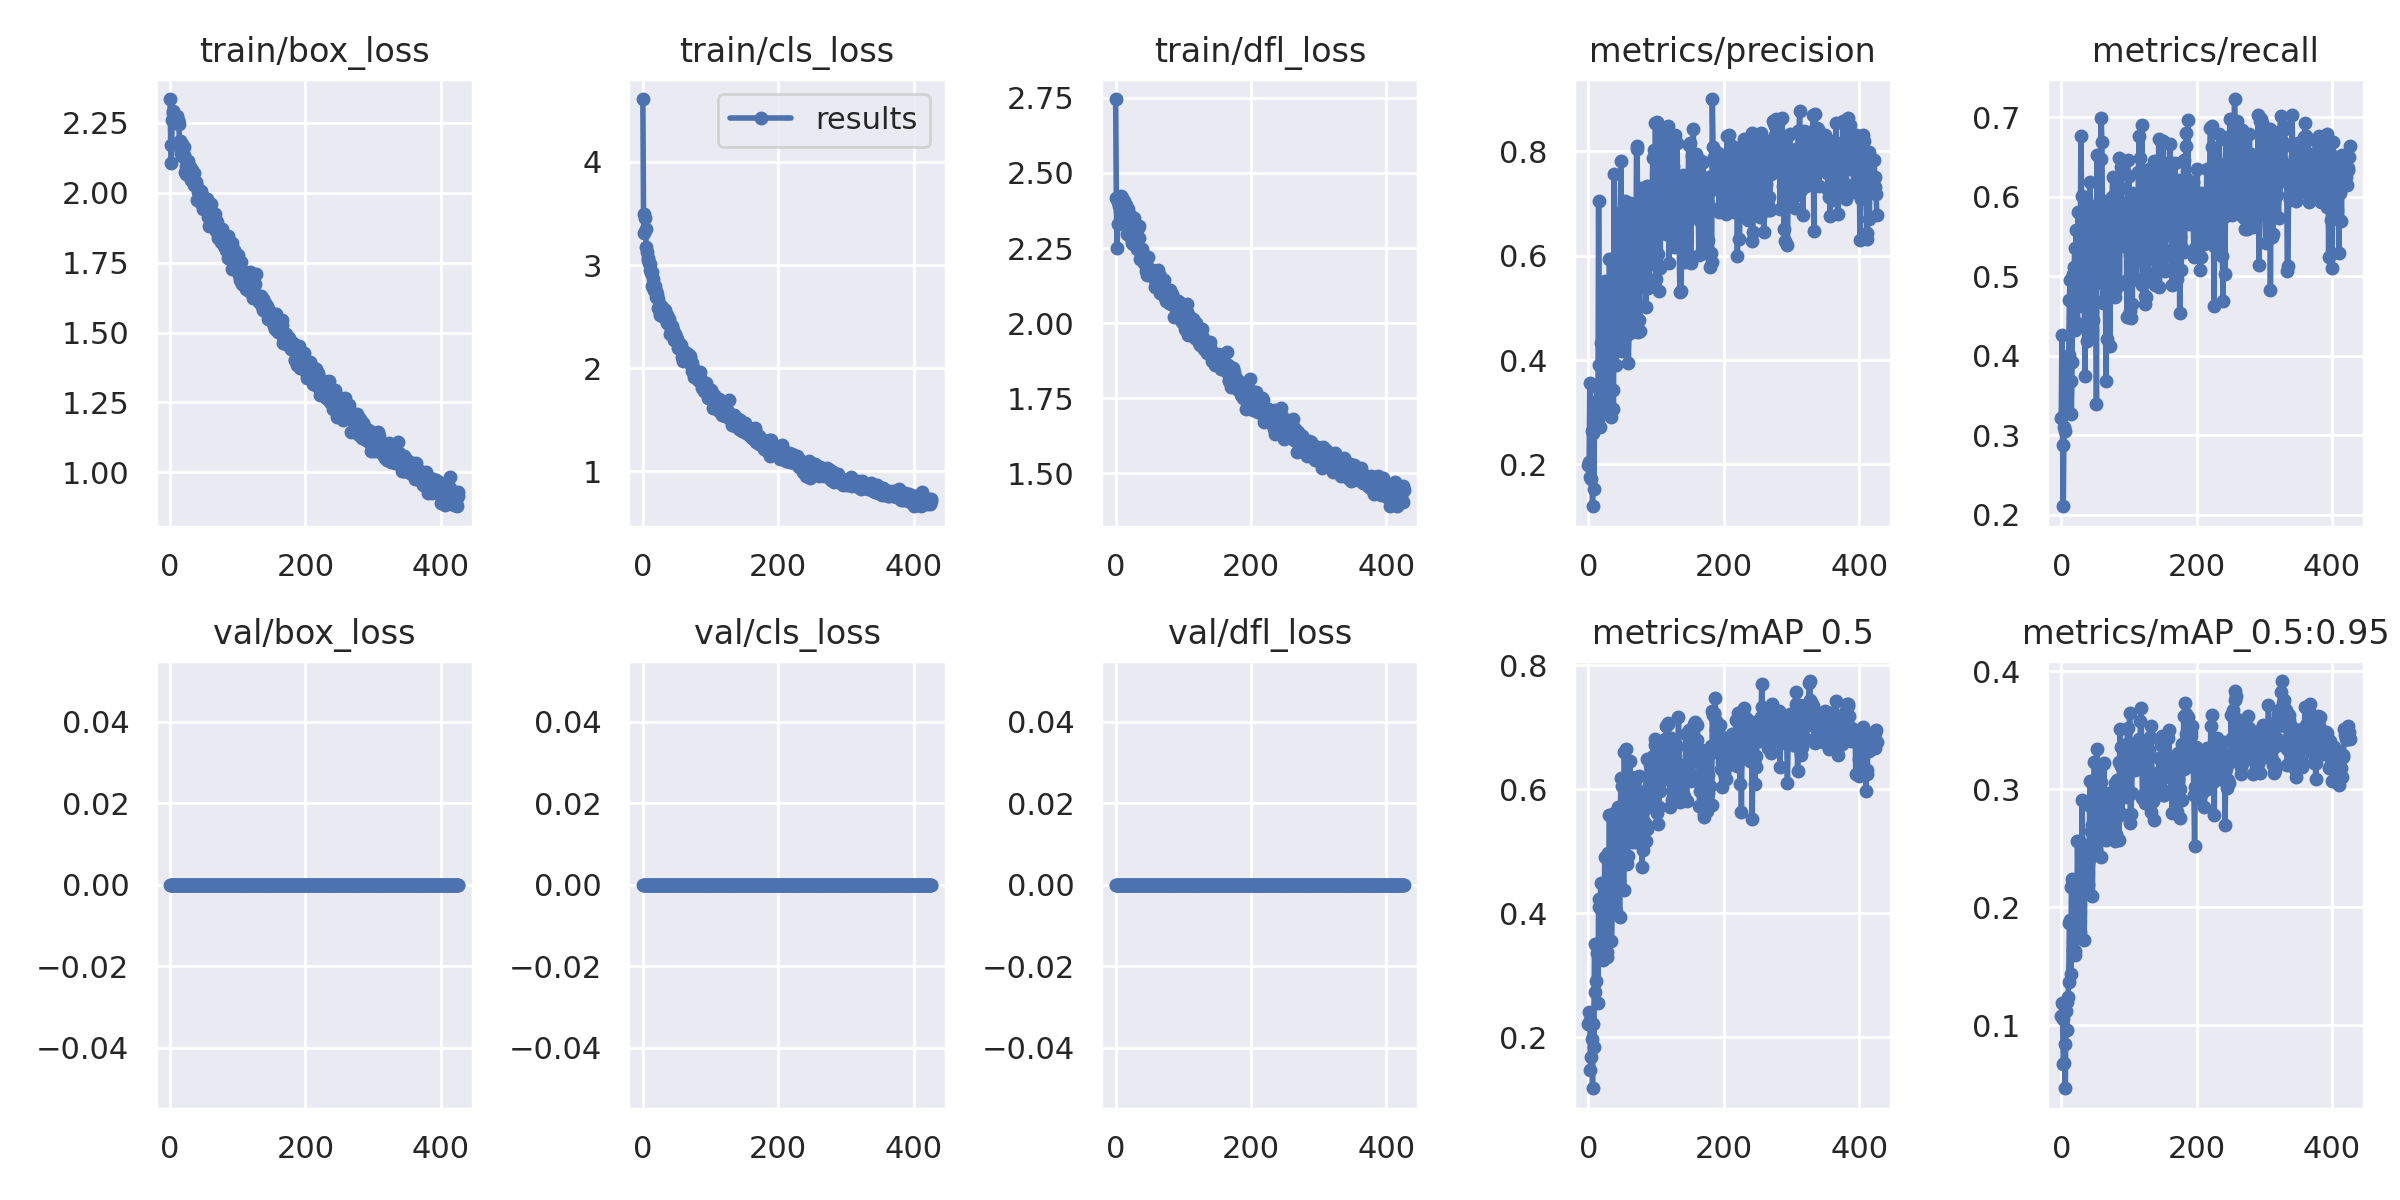

In [21]:

from IPython.display import Image

Image(filename=f"/content/yolov9/runs/train/yolov9-e-finetuning3/results.png", width=1000)

# Run the following code to view your confusion matrix:

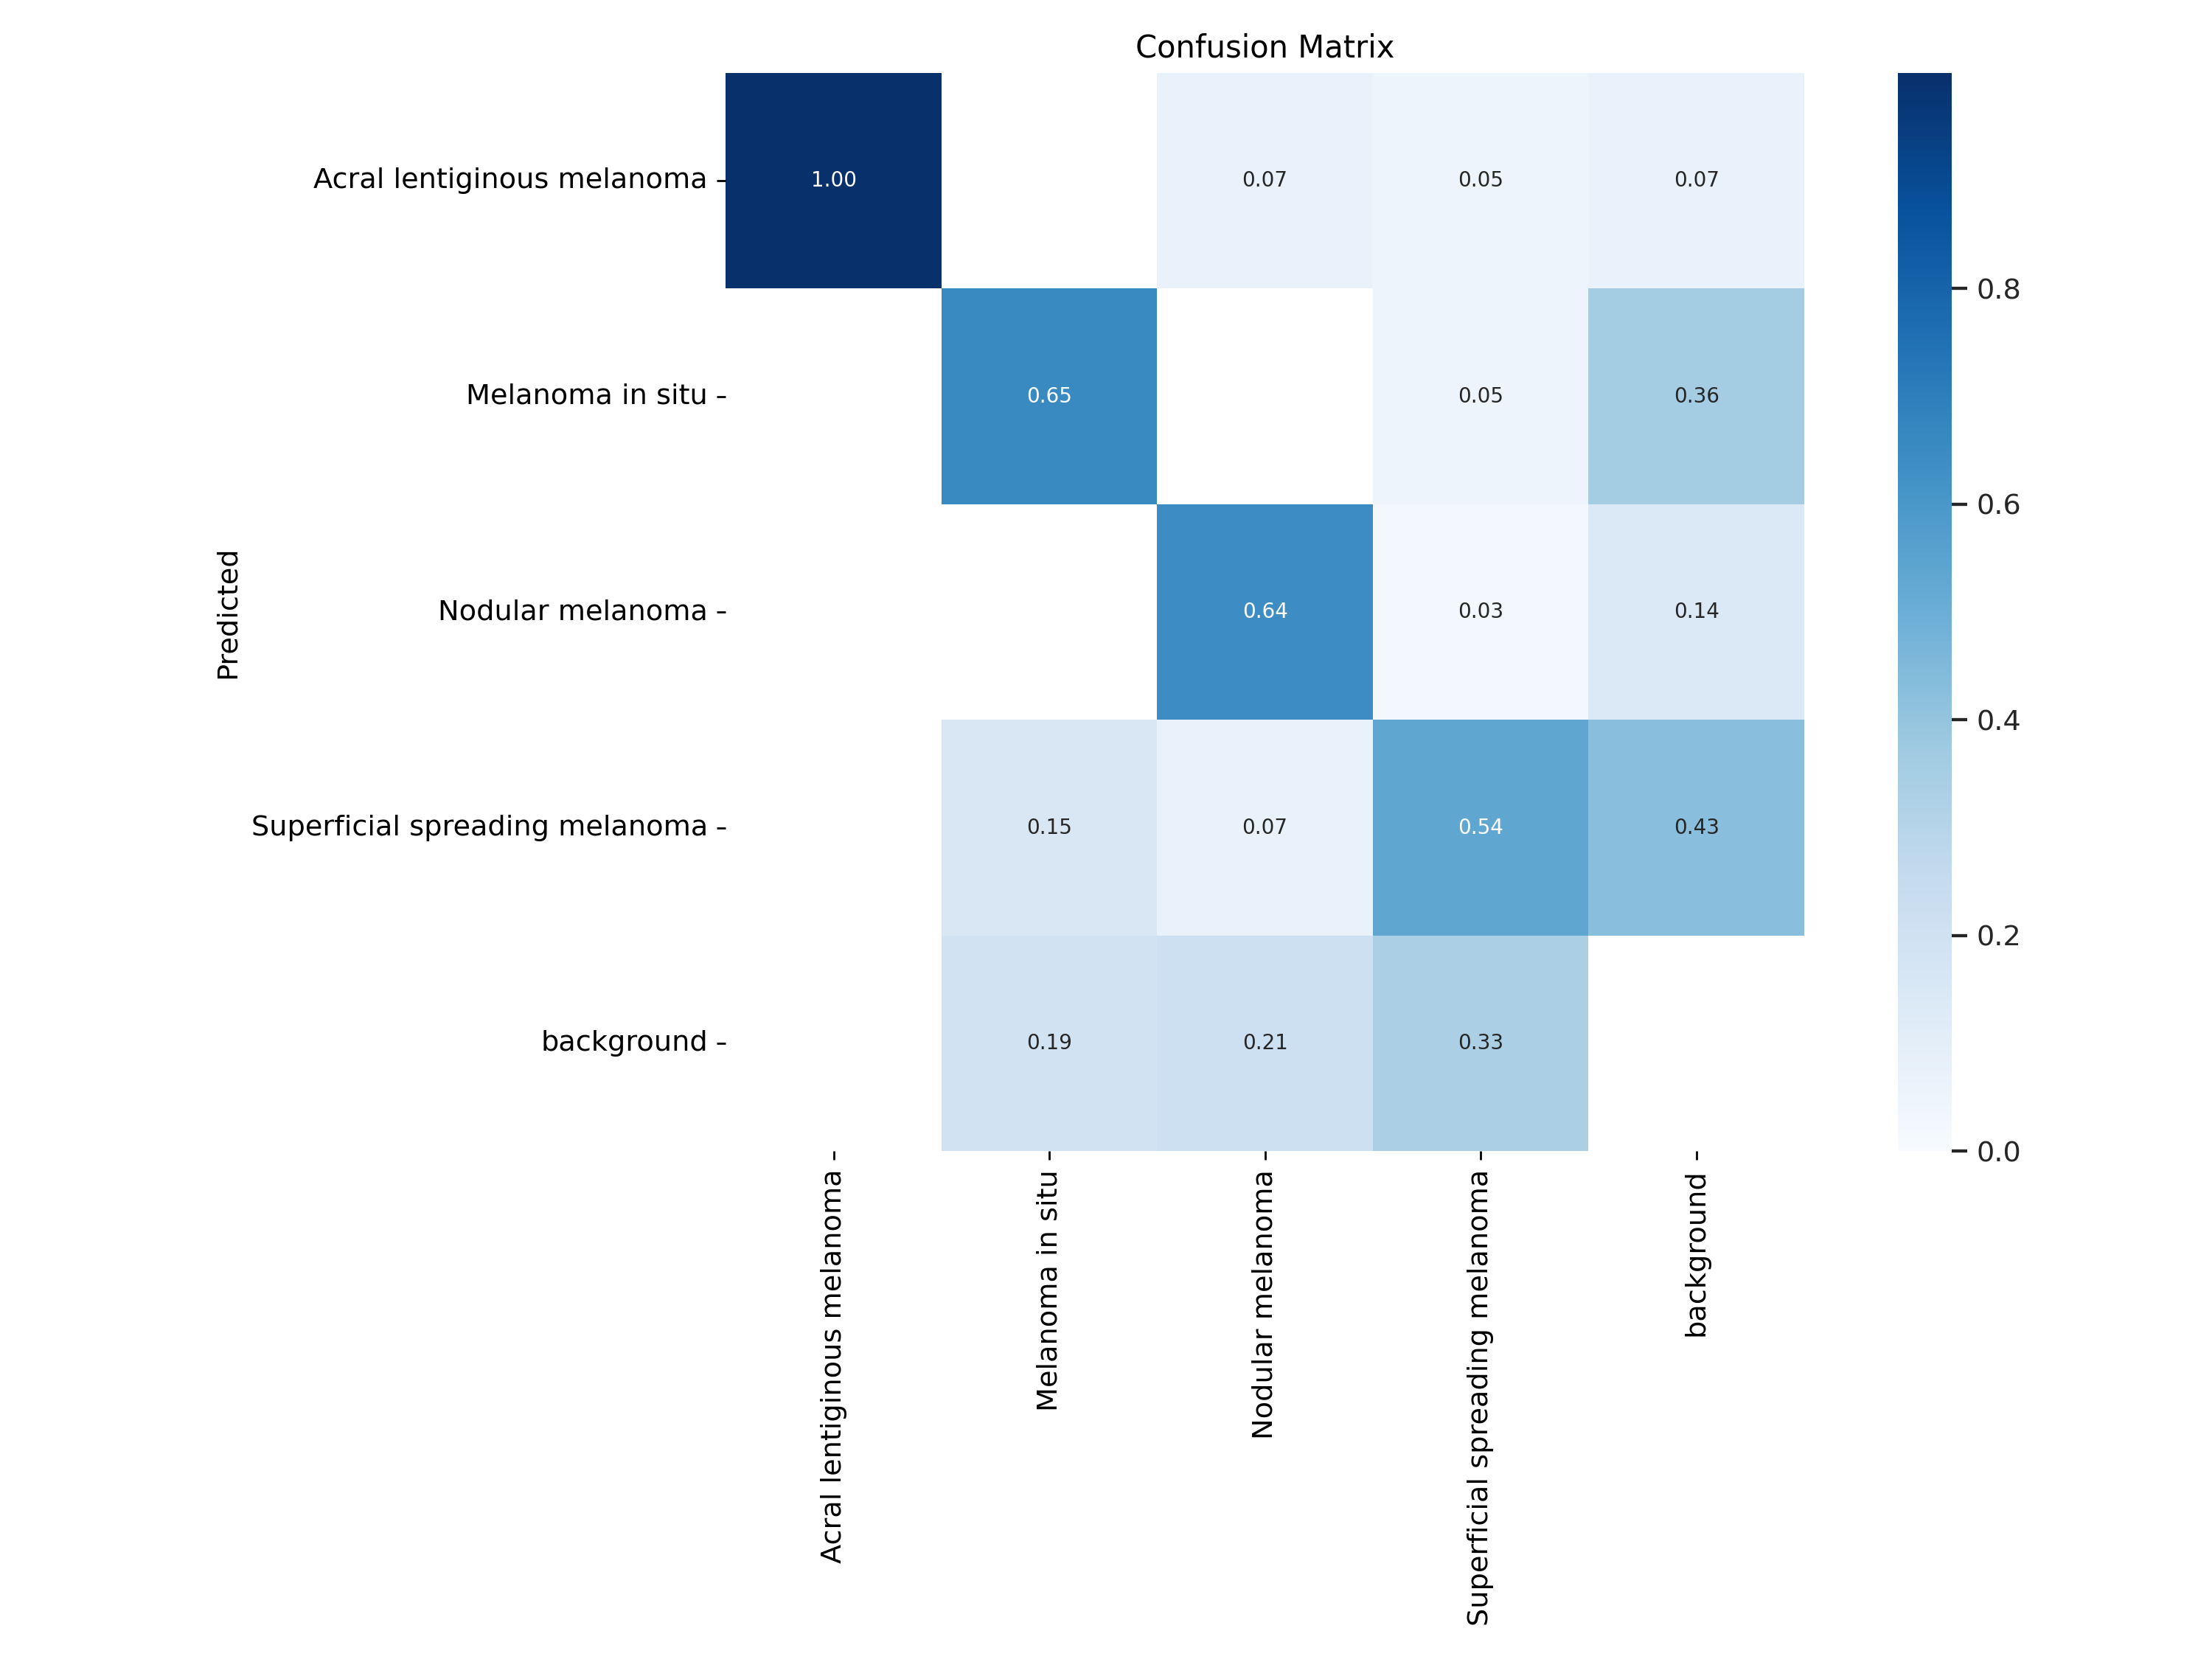

In [22]:
from IPython.display import Image

Image(filename=f"/content/yolov9/runs/train/yolov9-e-finetuning3/confusion_matrix.png", width=1000)

# Run the following code to see results from your model on a batch of images in your validation set:

In [ ]:

from IPython.display import Image

Image(filename=f"{HOME}/yolov9/runs/train/exp/val_batch0_pred.jpg", width=1000)

# Validate Custom Model

In [ ]:
%cd {HOME}/yolov9

!python val.py \
--img 640 --batch 16 --conf 0.001 --iou 0.7 --device 0 \
--data {dataset.location}/data.yaml \
--weights {HOME}/yolov9/runs/train/exp/weights/best.pt

In [13]:
# evaluate yolov9 models
!python val_dual.py --data '/content/yolov9/cancer-nbi-4/data.yaml' --img 640 --batch 16 --conf 0.001 --iou 0.7 --device 0 --weights '/content/yolov9/runs/train/exp/weights/best.pt'

val_dual: data=/content/yolov9/cancer-nbi-4/data.yaml, weights=['/content/yolov9/runs/train/exp/weights/best.pt'], batch_size=16, imgsz=640, conf_thres=0.001, iou_thres=0.7, max_det=300, task=val, device=0, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=runs/val, name=exp, exist_ok=False, half=False, dnn=False, min_items=0
YOLOv5 🚀 1e33dbb Python-3.10.12 torch-2.2.1+cu121 CUDA:0 (Tesla T4, 15102MiB)

Fusing layers... 
yolov9-e summary: 1119 layers, 69352952 parameters, 0 gradients, 243.3 GFLOPs
val: Scanning /content/yolov9/cancer-nbi-4/valid/labels.cache... 70 images, 0 backgrounds, 0 corrupt: 100% 70/70 [00:00<?, ?it/s]
/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
                 Class     Images  Instances     